# Data Understanding and Preparation

**Course:** Data Mining: Fundamental — University of Pisa (A.Y. 2026/2027)
**Dataset:** Seller-Level Vehicle Listings (`seller_info_dm1_2627.csv`)
**Goal of this notebook:** understand the data, clean it, prepare it, and export a
clean dataset ready to be consumed by the next steps (clustering, classification, regression).

The target variable is `seller_rating_class` (discretized seller rating: `low` / `medium` / `high`).

> Scope: this notebook stops at **Data Preparation & EDA**. No models are trained here.


## 0. Setup and imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)
RANDOM_STATE = 42

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)


pandas 3.0.6 | numpy 2.5.3 | seaborn 0.13.2


## 1.1 Data Semantics

### 1.1.1 Load dataset & general overview

One row per seller (`sp_id`), summarising the vehicle listings observed for that seller.


In [2]:
DATA_PATH = 'dataset/seller_info_dm1_2627.csv'

df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()


Shape: 13,843 rows x 33 columns


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,"404,771.000",30,"6,700.000",431.000,13.000,"193,193.500","2,011.000",9.000,2.000,258.500,NaN,17.000,23.500,38.650,41.300,21.000,68.900,195.350,77.100,0.133,0.000,0.000,0.000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,"336,590.000",17,"10,995.000",505.000,24.000,"87,589.000","2,012.000",7.000,2.000,182.000,"2,400.000",21.000,28.500,37.300,41.400,15.900,64.700,180.300,72.500,0.059,0.000,0.000,0.000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,"392,016.000",18,"7,645.000",632.000,43.000,"151,434.000","2,010.500",9.500,2.000,205.000,NaN,20.000,28.500,35.500,41.700,17.500,58.100,188.200,72.000,0.111,0.000,0.000,0.000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,"294,197.000",12,"23,449.000",479.000,18.000,"31,186.000","2,017.000",3.000,1.000,178.000,"2,500.000",25.000,35.000,38.650,42.300,16.500,57.900,190.050,72.050,0.000,0.000,0.000,0.000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,"372,085.000",14,"8,990.000",505.500,213.000,"144,471.500","2,007.500",12.000,1.500,240.000,"3,500.000",16.000,22.000,36.800,42.300,21.100,70.200,187.600,74.000,0.000,0.000,0.000,0.071,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium


In [3]:
# Column count by role
print(f'{df.shape[1]} columns total')
print('dtypes:\n', df.dtypes.value_counts().to_string())
df.info(show_counts=True)


33 columns total
dtypes:
 float64    22
str         8
int64       3
<class 'pandas.DataFrame'>
RangeIndex: 13843 entries, 0 to 13842
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   sp_id                        13843 non-null  float64
 1   n_listings                   13843 non-null  int64  
 2   price_median                 13843 non-null  float64
 3   savings_amount_median        13843 non-null  float64
 4   daysonmarket_median          13843 non-null  float64
 5   mileage_median               13842 non-null  float64
 6   year_median                  13843 non-null  float64
 7   vehicle_age_median           13842 non-null  float64
 8   owner_count_median           13804 non-null  float64
 9   horsepower_median            13837 non-null  float64
 10  engine_displacement_median   10450 non-null  float64
 11  city_fuel_economy_median     13827 non-null  float64
 12  highway_fuel_econ

### 1.1.2 Semantic description table

Each variable's meaning, the datatype it was read as, and its measurement scale.


In [4]:
semantics = [
    ('sp_id', 'Unique identifier of the seller/dealer', 'float64', 'Identifier (nominal)'),
    ('n_listings', 'Total number of vehicle listings of the seller', 'int64', 'Ratio (count)'),
    ('price_median', 'Median advertised price of listed vehicles', 'float64', 'Ratio'),
    ('savings_amount_median', 'Median advertised savings amount', 'float64', 'Ratio'),
    ('daysonmarket_median', 'Median days vehicles remained on market', 'float64', 'Ratio'),
    ('mileage_median', 'Median mileage of listed vehicles', 'float64', 'Ratio'),
    ('year_median', 'Median model year of listed vehicles', 'float64', 'Interval (year)'),
    ('vehicle_age_median', 'Median age of vehicles at listing time', 'float64', 'Ratio'),
    ('owner_count_median', 'Median number of previous owners', 'float64', 'Ratio (count)'),
    ('horsepower_median', 'Median horsepower', 'float64', 'Ratio'),
    ('engine_displacement_median', 'Median engine displacement (cc)', 'float64', 'Ratio'),
    ('city_fuel_economy_median', 'Median city fuel economy (mpg)', 'float64', 'Ratio'),
    ('highway_fuel_economy_median', 'Median highway fuel economy (mpg)', 'float64', 'Ratio'),
    ('back_legroom_median', 'Median rear-seat legroom (in)', 'float64', 'Ratio'),
    ('front_legroom_median', 'Median front-seat legroom (in)', 'float64', 'Ratio'),
    ('fuel_tank_volume_median', 'Median fuel-tank capacity (gal)', 'float64', 'Ratio'),
    ('height_median', 'Median vehicle height (in)', 'float64', 'Ratio'),
    ('length_median', 'Median vehicle length (in)', 'float64', 'Ratio'),
    ('width_median', 'Median vehicle width (in)', 'float64', 'Ratio'),
    ('pct_isCab', 'Proportion of listings previously used as cabs', 'float64', 'Ratio (proportion)'),
    ('pct_is_new', 'Proportion of listings classified as new', 'float64', 'Ratio (proportion)'),
    ('pct_salvage', 'Proportion of listings with salvage status', 'float64', 'Ratio (proportion)'),
    ('pct_theft_title', 'Proportion of listings with theft title', 'float64', 'Ratio (proportion)'),
    ('n_listing_days', 'Distinct calendar days with observed listings', 'int64', 'Ratio (count)'),
    ('listing_span_days', 'Days between earliest and latest listing', 'int64', 'Ratio'),
    ('dominant_body_type', 'Most frequent vehicle body type', 'str', 'Nominal'),
    ('dominant_fuel_type', 'Most frequent fuel type', 'str', 'Nominal'),
    ('dominant_transmission', 'Most frequent transmission type', 'str', 'Nominal'),
    ('dominant_wheel_system', 'Most frequent drivetrain configuration', 'str', 'Nominal'),
    ('dominant_listing_color', 'Most frequent exterior color', 'str', 'Nominal'),
    ('franchise_status', 'Franchise vs independent seller', 'str', 'Nominal'),
    ('new_used_profile', 'New/used inventory composition', 'str', 'Nominal'),
    ('seller_rating_class', 'Discretized target rating (low/medium/high)', 'str', 'Ordinal'),
]
semantic_df = pd.DataFrame(semantics, columns=['Variable', 'Description', 'Source datatype', 'Measurement scale'])
semantic_df


,Variable,Description,Source datatype,Measurement scale
0,sp_id,Unique identifier of the seller/dealer,float64,Identifier (nominal)
1,n_listings,Total number of vehicle listings of the seller,int64,Ratio (count)
2,price_median,Median advertised price of listed vehicles,float64,Ratio
3,savings_amount_median,Median advertised savings amount,float64,Ratio
4,daysonmarket_median,Median days vehicles remained on market,float64,Ratio
5,mileage_median,Median mileage of listed vehicles,float64,Ratio
6,year_median,Median model year of listed vehicles,float64,Interval (year)
7,vehicle_age_median,Median age of vehicles at listing time,float64,Ratio
8,owner_count_median,Median number of previous owners,float64,Ratio (count)
9,horsepower_median,Median horsepower,float64,Ratio


### 1.1.3 Initial datatype & semantic inconsistencies check

We compare the *stored* datatype against the *semantic* type and check for
impossible / out-of-domain values (the dataset is intentionally noisy).


In [5]:
categorical_cols = [
    'dominant_body_type', 'dominant_fuel_type', 'dominant_transmission',
    'dominant_wheel_system', 'dominant_listing_color',
    'franchise_status', 'new_used_profile', 'seller_rating_class',
]

# --- (a) Wrong stored datatypes -------------------------------------------
print('(a) Datatype issues:')
print(f"  sp_id              stored as {df['sp_id'].dtype}  -> should be integer identifier")
print(f"  owner_count_median stored as {df['owner_count_median'].dtype}  -> should be integer count")
print(f"  year_median        stored as {df['year_median'].dtype}  -> should be integer year")

# --- (b) Fractional medians (legitimate for medians, but worth noting) ----
# TODO: Check the reasoning for the data handling for year median and owner count median, does it have affect of the overall data / its interpretation
print('\n(b) Fractional medians (median of an even-sized set):')
year_frac = df.loc[df['year_median'] % 1 != 0, 'year_median']
print(f"  year_median        : {len(year_frac)} values, e.g. {sorted(float(x) for x in year_frac.unique())[:4]}")
owner_frac = df['owner_count_median'].dropna()
owner_frac = owner_frac[owner_frac % 1 != 0]
print(f"  owner_count_median : {len(owner_frac)} values, e.g. {sorted(float(x) for x in owner_frac.unique())[:4]}")


(a) Datatype issues:
  sp_id              stored as float64  -> should be integer identifier
  owner_count_median stored as float64  -> should be integer count
  year_median        stored as float64  -> should be integer year

(b) Fractional medians (median of an even-sized set):
  year_median        : 1010 values, e.g. [1968.5, 1969.5, 1975.5, 1986.5]
  owner_count_median : 407 values, e.g. [1.5, 2.5, 3.5, 4.5]


## 1.2 Distribution of Variables and Statistics

### 1.2.1 Summary of statistics


In [6]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove('sp_id')   # identifier, not a measurement

df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
n_listings,"13,843.000",118.095,137.063,5.000,25.000,70.000,168.000,"4,959.000"
price_median,"13,843.000","23,106.140","14,365.067","1,699.000","12,495.000","22,385.000","29,888.000","236,438.000"
savings_amount_median,"13,843.000",446.213,519.462,0.000,0.000,358.000,734.000,"9,333.000"
daysonmarket_median,"13,843.000",49.147,56.060,0.000,26.000,36.000,51.000,"1,987.000"
mileage_median,"13,842.000","51,463.271","51,845.462",0.000,25.000,"33,596.500","96,915.750","238,541.000"
year_median,"13,843.000","2,015.949",4.722,"1,960.000","2,013.000","2,017.000","2,020.000","2,021.000"
vehicle_age_median,"13,842.000",4.083,4.633,0.000,0.000,3.000,7.000,60.000
owner_count_median,"13,804.000",1.434,0.624,1.000,1.000,1.000,2.000,6.000
horsepower_median,"13,837.000",240.903,56.993,78.000,188.000,243.000,283.000,630.000
engine_displacement_median,"10,450.000","2,925.081",808.084,"1,200.000","2,400.000","2,500.000","3,500.000","6,800.000"


In [7]:
# Categorical overview
for c in categorical_cols:
    print(f'--- {c} ({df[c].nunique(dropna=False)} levels) ---')
    print(df[c].value_counts(dropna=False).to_string())
    print()


--- dominant_body_type (9 levels) ---
dominant_body_type
suv_crossover    8920
sedan            3044
pickup_truck     1424
coupe             167
hatchback          97
van                82
convertible        63
minivan            39
wagon               7

--- dominant_fuel_type (7 levels) ---
dominant_fuel_type
gasoline             13658
flex_fuel_vehicle       91
diesel                  52
biodiesel               16
hybrid                  13
electric                12
unknown                  1

--- dominant_transmission (4 levels) ---
dominant_transmission
a          12976
cvt          847
m             14
unknown        6

--- dominant_wheel_system (6 levels) ---
dominant_wheel_system
NaN    10518
fwd     1781
awd      724
4wd      668
rwd      129
4x2       23

--- dominant_listing_color (11 levels) ---
dominant_listing_color
white      5167
black      4475
unknown    1510
silver      992
gray        875
red         417
blue        372
brown        17
green        12
gold         

### 1.2.2 Distribution of numerical variables (histograms & skewness)


In [8]:
skew = df[numeric_cols].skew().sort_values(ascending=False)
skew_df = skew.to_frame('skewness')
skew_df['interpretation'] = skew_df['skewness'].apply(
    lambda s: 'highly right-skewed' if s > 1 else ('left-skewed' if s < -1 else 'approx. symmetric'))
skew_df


,skewness,interpretation
pct_theft_title,14.107,highly right-skewed
pct_salvage,10.340,highly right-skewed
daysonmarket_median,8.755,highly right-skewed
city_fuel_economy_median,8.098,highly right-skewed
n_listings,5.247,highly right-skewed
highway_fuel_economy_median,3.876,highly right-skewed
front_legroom_median,3.491,highly right-skewed
price_median,3.446,highly right-skewed
savings_amount_median,2.396,highly right-skewed
vehicle_age_median,2.322,highly right-skewed


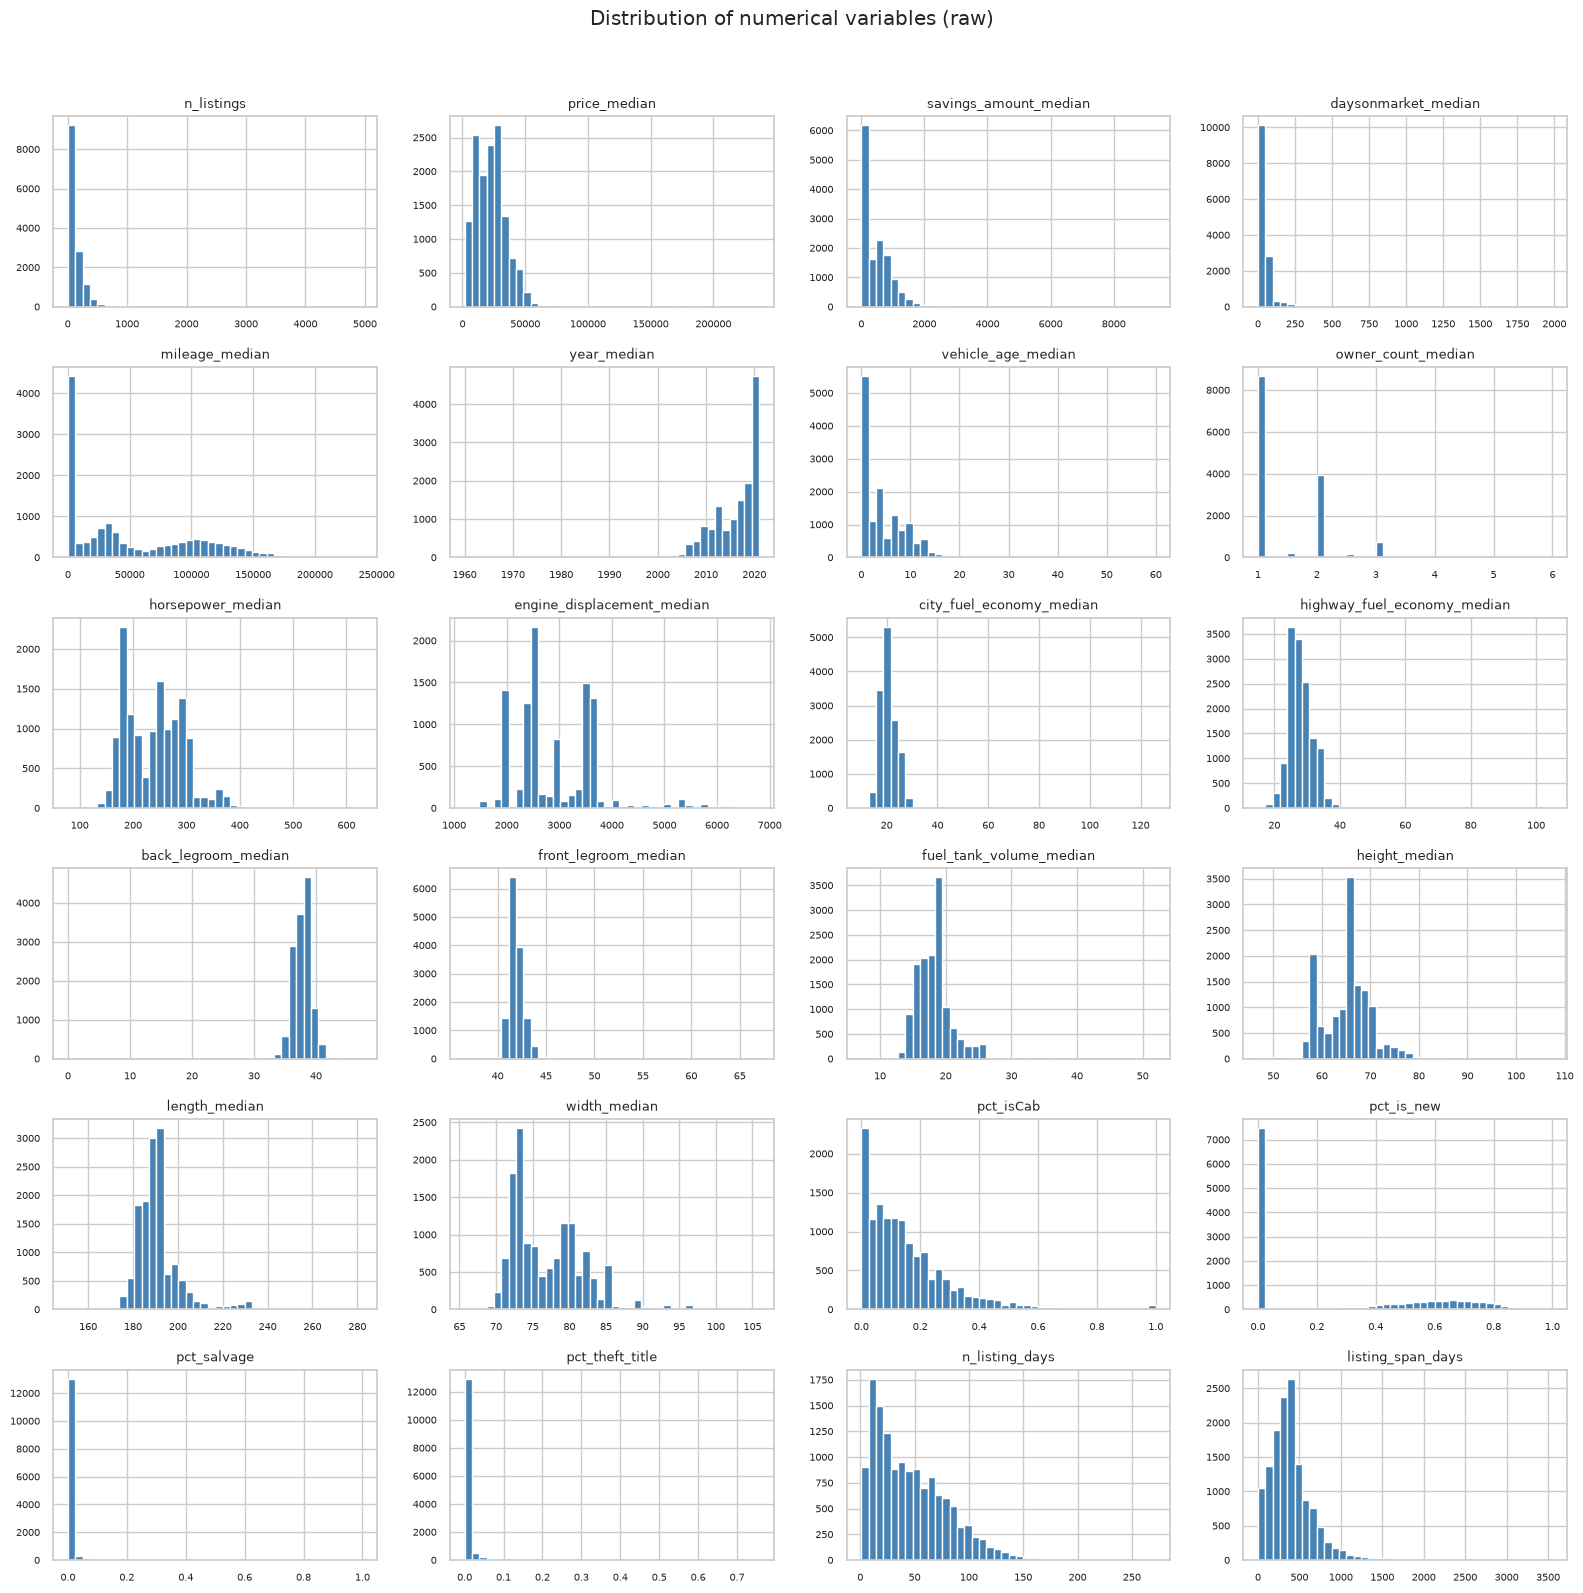

In [9]:
n = len(numeric_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 2.6))
axes = axes.ravel()
for ax, col in zip(axes, numeric_cols):
    df[col].dropna().hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes[n:]:
    ax.axis('off')
plt.suptitle('Distribution of numerical variables (raw)', y=1.02)
plt.tight_layout()
plt.show()


### 1.2.3 Distribution of categorical variables


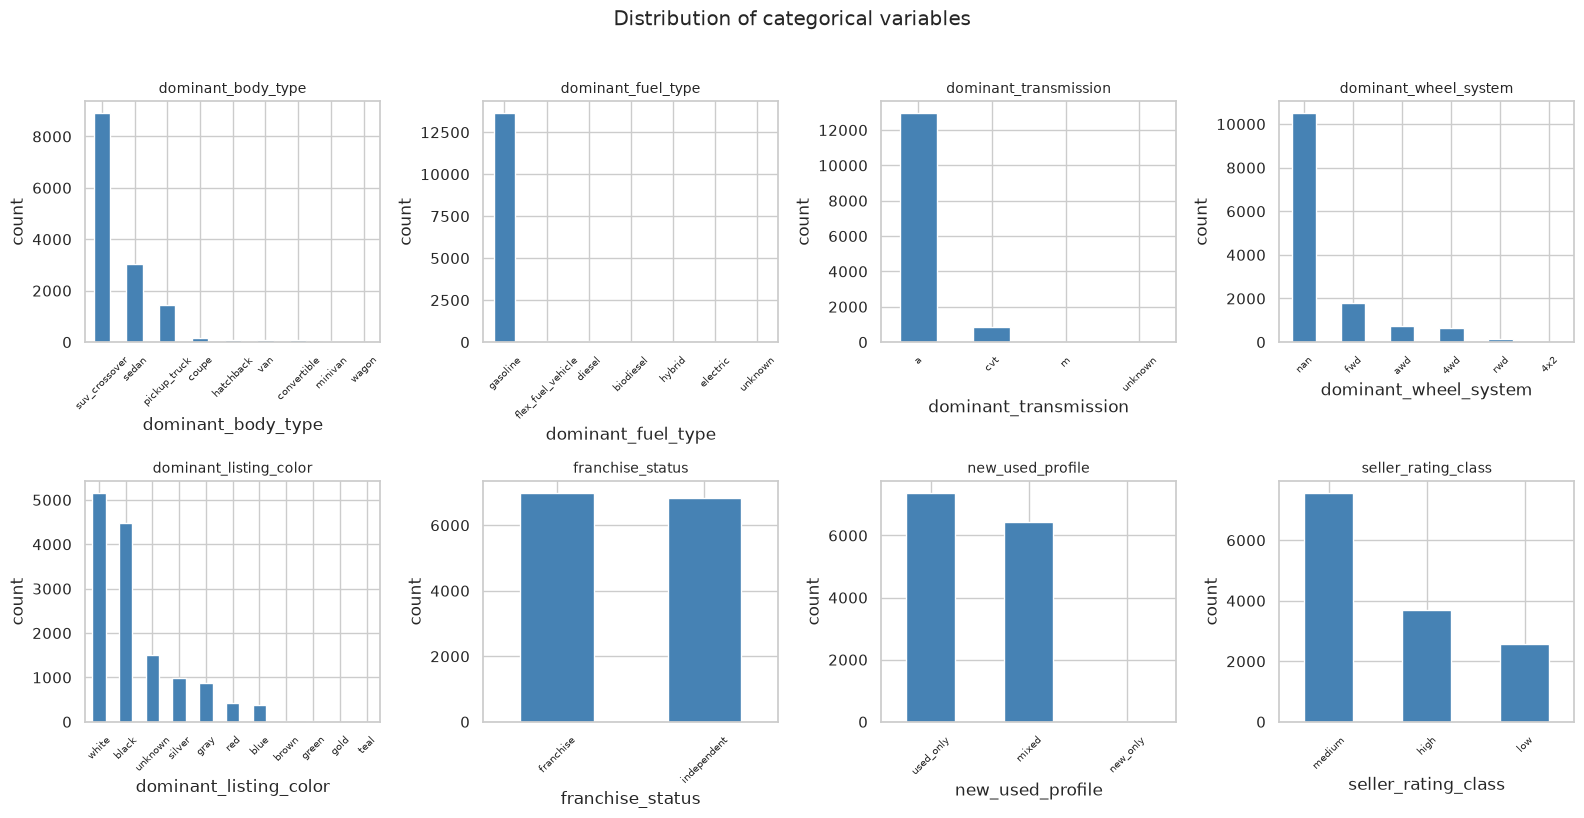

Target class balance (seller_rating_class):
seller_rating_class
medium   0.547
high     0.266
low      0.186


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for ax, col in zip(axes, categorical_cols):
    vc = df[col].value_counts(dropna=False)
    vc.plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.set_ylabel('count')
plt.suptitle('Distribution of categorical variables', y=1.02)
plt.tight_layout()
plt.show()

print('Target class balance (seller_rating_class):')
print(df['seller_rating_class'].value_counts(normalize=True).round(4).to_string())


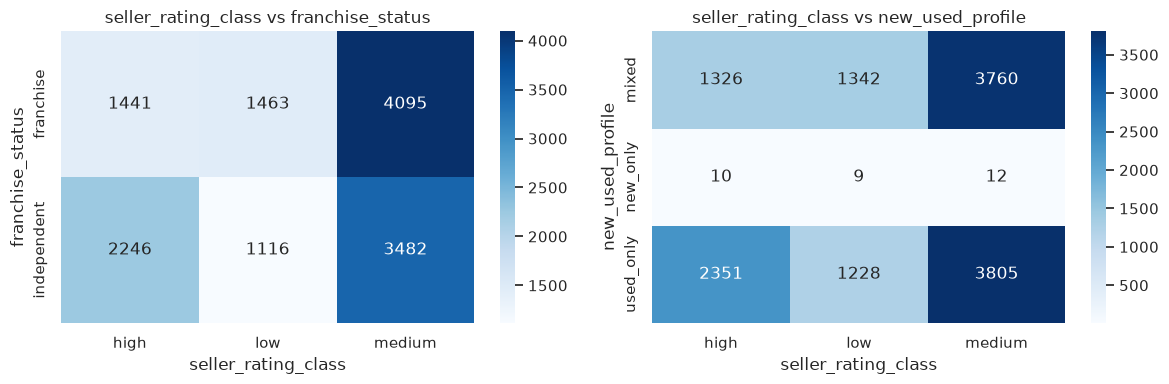

In [11]:
# Cross-tab: target vs the two seller-profile variables
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['franchise_status', 'new_used_profile']):
    ct = pd.crosstab(df[col], df['seller_rating_class'])
    sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'seller_rating_class vs {col}')
plt.tight_layout()
plt.show()


## 1.3 Assessment of Data Quality

### 1.3.1 Missing value analysis & imputation strategy


In [12]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
missing_df


,missing_count,missing_%
dominant_wheel_system,10518,75.980
engine_displacement_median,3393,24.510
owner_count_median,39,0.280
pct_salvage,27,0.200
pct_theft_title,27,0.200
pct_isCab,27,0.200
back_legroom_median,19,0.140
highway_fuel_economy_median,16,0.120
city_fuel_economy_median,16,0.120
front_legroom_median,7,0.050


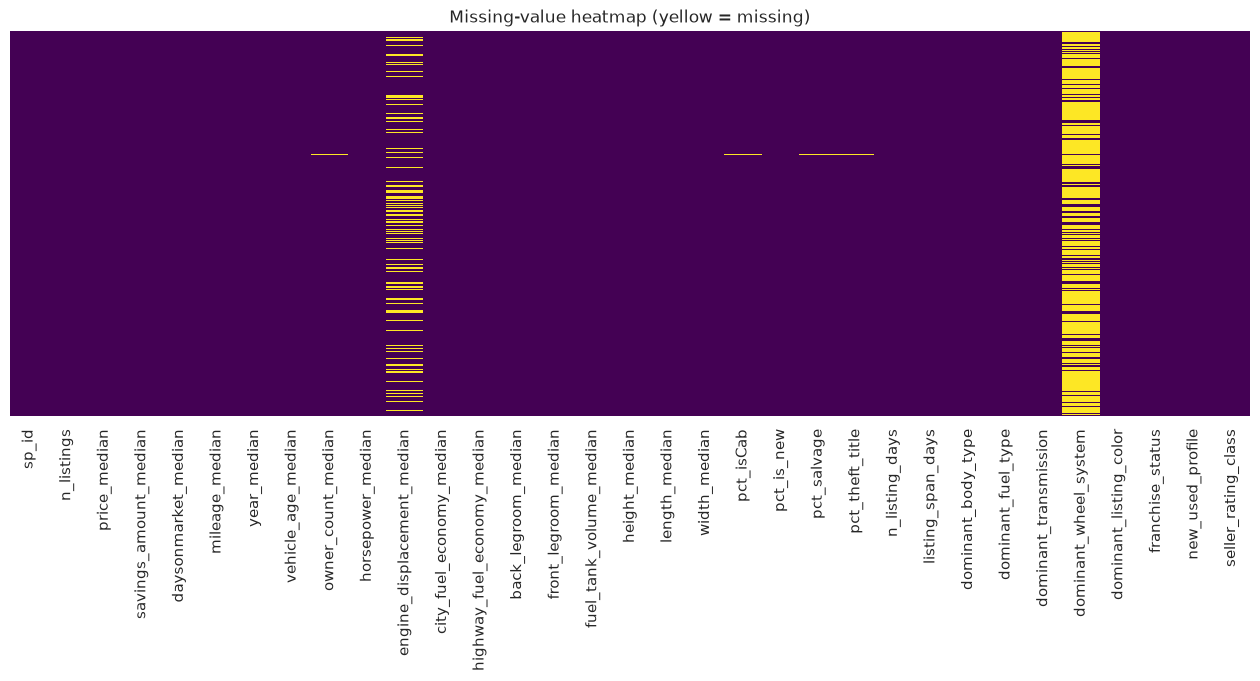

In [13]:
plt.figure(figsize=(16, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing-value heatmap (yellow = missing)')
plt.show()


**Imputation decision.**

* `dominant_wheel_system` — **76.0% missing** → too sparse to impute meaningfully; **dropped**.
* `engine_displacement_median` — 24.5% missing; kept here but **re-examined in §1.5** (redundant + missing).
* All other numeric columns have < 0.3% missing → **median imputation** (robust to outliers).
* Categorical columns use the label `unknown` rather than `NaN`, so no imputation is needed there.

We also fix the wrong datatypes here (`sp_id` → int, `owner_count_median` → int) and expand the
abbreviated transmission labels (`a` → automatic, `m` → manual).


In [14]:
# Work on a copy so the raw data stays available for reference
df_clean = df.copy()

# --- Fix wrong datatypes -----------------------------------------------------
df_clean['sp_id'] = df_clean['sp_id'].astype('int64')                 # identifier
df_clean['owner_count_median'] = df_clean['owner_count_median'].round().astype('Int64')  # discrete count

# --- Expand abbreviated categorical labels -----------------------------------
df_clean['dominant_transmission'] = df_clean['dominant_transmission'].replace({
    'a': 'automatic', 'm': 'manual', 'cvt': 'cvt'})

# --- Drop the near-empty column ----------------------------------------------
df_clean = df_clean.drop(columns=['dominant_wheel_system'])
print('dropped dominant_wheel_system (76% missing); remaining columns:', df_clean.shape[1])
print('sp_id dtype now:', df_clean['sp_id'].dtype, '| owner_count dtype now:', df_clean['owner_count_median'].dtype)
print('transmission levels now:', sorted(df_clean['dominant_transmission'].unique()))


dropped dominant_wheel_system (76% missing); remaining columns: 32
sp_id dtype now: int64 | owner_count dtype now: Int64
transmission levels now: ['automatic', 'cvt', 'manual', 'unknown']


### 1.3.2 Outlier and noise detection (boxplots, semantic checks & filtering)


/tmp/ipykernel_132590/2490634850.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False, widths=0.6)
/tmp/ipykernel_132590/2490634850.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False, widths=0.6)
/tmp/ipykernel_132590/2490634850.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False, widths=0.6)
/tmp/ipykernel_132590/2490634850.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False, widths=0

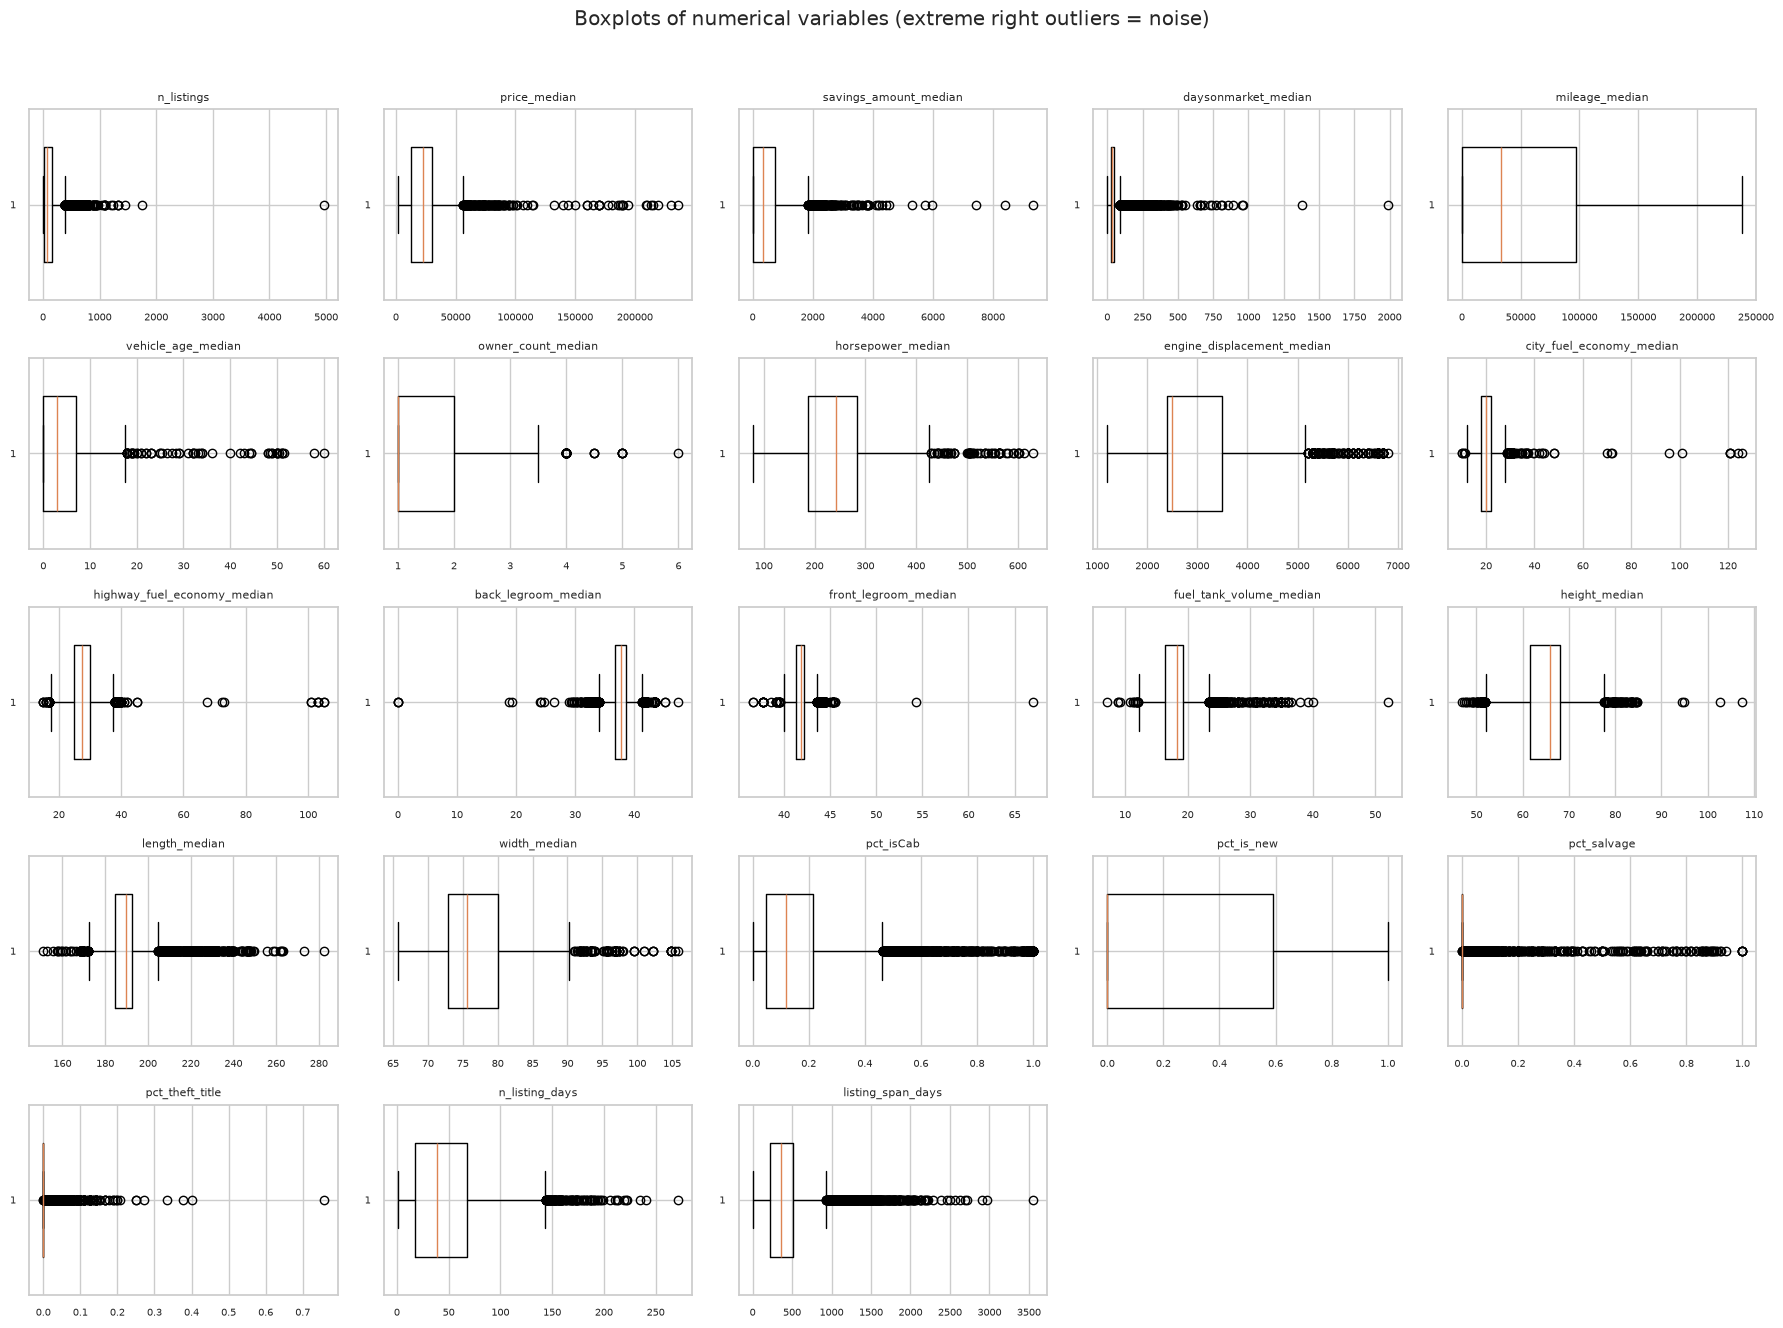

In [15]:
# Boxplots reveal the severe right tails / injected noise
cont = [c for c in numeric_cols if c != 'year_median']
ncols = 5
nrows = int(np.ceil(len(cont) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 2.6))
axes = axes.ravel()
for ax, col in zip(axes, cont):
    ax.boxplot(df[col].dropna(), vert=False, widths=0.6)
    ax.set_title(col, fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[len(cont):]:
    ax.axis('off')
plt.suptitle('Boxplots of numerical variables (extreme right outliers = noise)', y=1.02)
plt.tight_layout()
plt.show()


**Outlier strategy.**

The right tails contain clearly impossible values (e.g. city fuel economy of 126 mpg,
vehicle height of 107 in, front legroom of 67 in), which are the *injected* noise/errors.

We apply two steps:

1. **Semantic fix** — a value that is physically impossible (`back_legroom_median == 0`)
   is set to `NaN` and later imputed.
2. **Winsorization** — each heavy-tailed continuous feature is clipped to its 99th
   percentile. This caps the noisiest top 1% **without deleting any seller** (all
   13,843 rows are kept). The IQR-1.5 rule is rejected because on this heavily
   skewed data it would flag a large share of legitimate values.


In [16]:
# --- Step 1: semantic fix (impossible value) ---------------------------------
n_bad = (df_clean['back_legroom_median'] == 0).sum()
df_clean.loc[df_clean['back_legroom_median'] == 0, 'back_legroom_median'] = np.nan
print(f'back_legroom_median == 0 (impossible) fixed: {n_bad} rows -> NaN')

# --- Step 2: winsorize the heavy-tailed continuous features ------------------
winsorize_cols = [
    'n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median',
    'mileage_median', 'vehicle_age_median', 'horsepower_median',
    'engine_displacement_median', 'city_fuel_economy_median', 'highway_fuel_economy_median',
    'back_legroom_median', 'front_legroom_median', 'fuel_tank_volume_median',
    'height_median', 'length_median', 'width_median', 'n_listing_days', 'listing_span_days',
]
# owner_count (discrete 1-6) and the proportions (already in [0,1]) are excluded.

winsor_bounds = {}
for col in winsorize_cols:
    upper = df_clean[col].quantile(0.99)
    winsor_bounds[col] = upper
    df_clean[col] = df_clean[col].clip(upper=upper)

print('\nWinsorization upper bounds (99th percentile):')
for col, upper in winsor_bounds.items():
    print(f'  {col:30s} -> {upper:10.2f}')


back_legroom_median == 0 (impossible) fixed: 3 rows -> NaN

Winsorization upper bounds (99th percentile):
  n_listings                     ->     572.48
  price_median                   ->   59920.57
  savings_amount_median          ->    2086.22
  daysonmarket_median            ->     280.00
  mileage_median                 ->  174295.00
  vehicle_age_median             ->      15.00
  horsepower_median              ->     385.00
  engine_displacement_median     ->    5700.00
  city_fuel_economy_median       ->      28.00
  highway_fuel_economy_median    ->      37.00
  back_legroom_median            ->      41.20
  front_legroom_median           ->      43.90
  fuel_tank_volume_median        ->      28.00
  height_median                  ->      77.50
  length_median                  ->     231.83
  width_median                   ->      93.40
  n_listing_days                 ->     142.00
  listing_span_days              ->    1493.58


### 1.3.3 Impute remaining missing values (median)


In [17]:
# Impute numeric missings with the (now robust) median
for col in df_clean.select_dtypes(include=[np.number]).columns:
    if df_clean[col].isna().any():
        med = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(med)
        print(f'  imputed {col:30s} median = {med:10.2f}')

# owner_count has no NaN left -> back to a plain integer
df_clean['owner_count_median'] = df_clean['owner_count_median'].astype('int64')

print('\nMissing values remaining:', df_clean.isna().sum().sum())
print('\nsp_id dtype:', df_clean['sp_id'].dtype, '| owner_count dtype:', df_clean['owner_count_median'].dtype)


  imputed mileage_median                 median =   33596.50
  imputed vehicle_age_median             median =       3.00
  imputed owner_count_median             median =       1.00
  imputed horsepower_median              median =     243.00
  imputed engine_displacement_median     median =    2500.00
  imputed city_fuel_economy_median       median =      20.00
  imputed highway_fuel_economy_median    median =      27.50
  imputed back_legroom_median            median =      37.80
  imputed front_legroom_median           median =      41.80
  imputed fuel_tank_volume_median        median =      18.25
  imputed height_median                  median =      66.00
  imputed length_median                  median =     189.80
  imputed width_median                   median =      75.55
  imputed pct_isCab                      median =       0.12
  imputed pct_salvage                    median =       0.00
  imputed pct_theft_title                median =       0.00

Missing values remainin

## 1.4 Variables Transformation

### 1.4.1 Log-transformation for highly skewed variables

After cleaning, features whose skewness is still > 1 are transformed with
`log1p(x) = log(x + 1)` to make them more symmetric (many values, incl. some 0s).


In [18]:
num_clean = df_clean.select_dtypes(include=[np.number]).drop(columns=['sp_id']).columns.tolist()
skew_after = df_clean[num_clean].skew()

# log-transform the highly right-skewed continuous features (skip the discrete owner count)
highly_skewed = [c for c in num_clean if skew_after[c] > 1 and c != 'owner_count_median']
print('Features with skew > 1 (log1p-transformed):')
print(highly_skewed)

df_log = df_clean.copy()
for col in highly_skewed:
    df_log[col] = np.log1p(df_log[col])

compare = pd.DataFrame({'skew_before': skew_after, 'skew_after_log1p': df_log[num_clean].skew()})
compare.loc[highly_skewed].round(2)


Features with skew > 1 (log1p-transformed):
['n_listings', 'savings_amount_median', 'daysonmarket_median', 'engine_displacement_median', 'fuel_tank_volume_median', 'length_median', 'pct_isCab', 'pct_salvage', 'pct_theft_title', 'listing_span_days']


,skew_before,skew_after_log1p
n_listings,1.620,-0.160
savings_amount_median,1.060,-0.410
daysonmarket_median,3.310,0.290
engine_displacement_median,1.540,0.710
fuel_tank_volume_median,1.070,0.540
length_median,1.900,1.620
pct_isCab,2.040,1.470
pct_salvage,10.350,9.330
pct_theft_title,14.120,10.640
listing_span_days,1.490,-1.270


### 1.4.2 Feature scaling (Z-score vs Min-Max)

We standardize numeric features with **Z-score** (`StandardScaler`, mean 0, std 1):

* **Z-score** keeps the relative scale and is the safe default for clustering,
  k-NN and regularized regression.
* **Min-Max** compresses to [0, 1] and is *sensitive to outliers* (a single large
  value shrinks the rest into a tiny range) — so it is **not** used here.

Categorical features are one-hot encoded afterwards (needed for distance-based methods).


In [19]:
scaler = StandardScaler()
df_scaled = df_log.copy()
df_scaled[num_clean] = scaler.fit_transform(df_log[num_clean])

print('After Z-score (numeric features):')
df_scaled[num_clean].describe().T.round(3)


After Z-score (numeric features):


,count,mean,std,min,25%,50%,75%,max
n_listings,"13,843.000",-0.000,1.000,-2.085,-0.809,0.065,0.819,1.882
price_median,"13,843.000",-0.000,1.000,-1.742,-0.848,-0.029,0.592,3.078
savings_amount_median,"13,843.000",-0.000,1.000,-1.267,-1.267,0.619,0.848,1.183
daysonmarket_median,"13,843.000",0.000,1.000,-5.810,-0.582,-0.082,0.458,3.134
mileage_median,"13,843.000",-0.000,1.000,-0.997,-0.996,-0.344,0.885,2.387
year_median,"13,843.000",-0.000,1.000,-11.849,-0.625,0.223,0.858,1.070
vehicle_age_median,"13,843.000",-0.000,1.000,-0.960,-0.960,-0.239,0.722,2.645
owner_count_median,"13,843.000",0.000,1.000,-0.700,-0.700,-0.700,0.908,7.338
horsepower_median,"13,843.000",0.000,1.000,-2.984,-0.960,0.051,0.787,2.663
engine_displacement_median,"13,843.000",0.000,1.000,-3.626,-0.404,-0.404,1.073,3.215


In [20]:
# One-hot encode categorical features (target and id are left untouched)
cat_features = [
    'dominant_body_type', 'dominant_fuel_type', 'dominant_transmission',
    'dominant_listing_color', 'franchise_status', 'new_used_profile',
]
df_encoded = pd.get_dummies(df_scaled, columns=cat_features, dtype=int)
print('One-hot encoded shape:', df_encoded.shape)
df_encoded.head()


One-hot encoded shape: (13843, 62)


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,seller_rating_class,dominant_body_type_convertible,dominant_body_type_coupe,dominant_body_type_hatchback,dominant_body_type_minivan,dominant_body_type_pickup_truck,dominant_body_type_sedan,dominant_body_type_suv_crossover,dominant_body_type_van,dominant_body_type_wagon,dominant_fuel_type_biodiesel,dominant_fuel_type_diesel,dominant_fuel_type_electric,dominant_fuel_type_flex_fuel_vehicle,dominant_fuel_type_gasoline,dominant_fuel_type_hybrid,dominant_fuel_type_unknown,dominant_transmission_automatic,dominant_transmission_cvt,dominant_transmission_manual,dominant_transmission_unknown,dominant_listing_color_black,dominant_listing_color_blue,dominant_listing_color_brown,dominant_listing_color_gold,dominant_listing_color_gray,dominant_listing_color_green,dominant_listing_color_red,dominant_listing_color_silver,dominant_listing_color_teal,dominant_listing_color_unknown,dominant_listing_color_white,franchise_status_franchise,franchise_status_independent,new_used_profile_mixed,new_used_profile_new_only,new_used_profile_used_only
0,404771,-0.656,-1.328,0.678,-1.624,2.387,-1.048,1.203,0.908,0.336,-0.404,-1.136,-1.232,0.658,-0.814,1.047,0.775,0.474,0.022,-0.101,-0.845,-0.164,-0.257,-0.945,-0.918,medium,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1
1,336590,-1.129,-0.972,0.729,-0.704,0.704,-0.836,0.722,0.908,-1.071,-0.583,0.136,0.191,-0.284,-0.675,-0.924,-0.088,-1.137,-0.927,-0.650,-0.845,-0.164,-0.257,-0.975,0.802,medium,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1
2,392016,-1.082,-1.250,0.800,0.193,1.943,-1.154,1.323,0.908,-0.648,-0.404,-0.182,0.191,-1.540,-0.256,-0.248,-1.445,-0.275,-1.030,-0.261,-0.845,-0.164,-0.257,-0.945,-1.530,low,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,294197,-1.412,0.059,0.712,-1.139,-0.391,0.223,-0.239,-0.700,-1.144,-0.404,1.408,2.042,0.658,0.582,-0.663,-1.487,-0.078,-1.020,-1.112,-0.845,-0.164,-0.257,-1.188,0.082,medium,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1
4,372085,-1.288,-1.138,0.729,2.702,1.808,-1.789,1.924,0.908,-0.004,1.073,-1.454,-1.659,-0.633,0.582,1.081,1.043,-0.339,-0.617,-1.112,-0.845,-0.164,4.400,-1.218,-0.009,medium,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1


## 1.5 Pairwise Correlations and Variable Elimination

### 1.5.1 Pairwise scatter plots


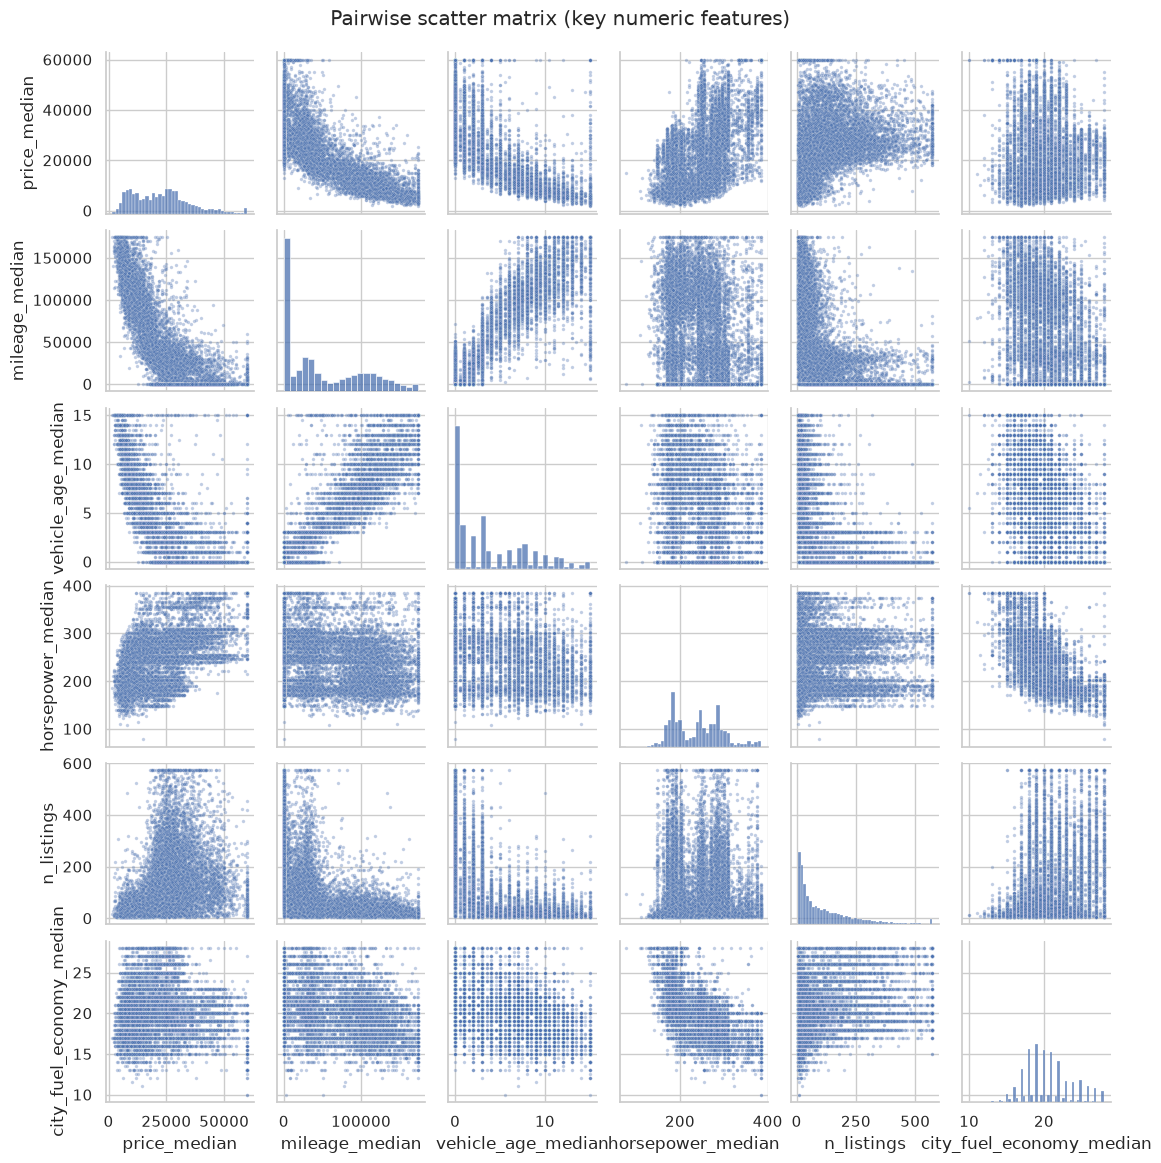

In [21]:
# Pairwise scatter matrix of a few representative numeric features
key = ['price_median', 'mileage_median', 'vehicle_age_median', 'horsepower_median',
       'n_listings', 'city_fuel_economy_median']
sns.pairplot(df_clean[key], height=1.9, plot_kws={'s': 6, 'alpha': 0.35})
plt.suptitle('Pairwise scatter matrix (key numeric features)', y=1.02)
plt.show()


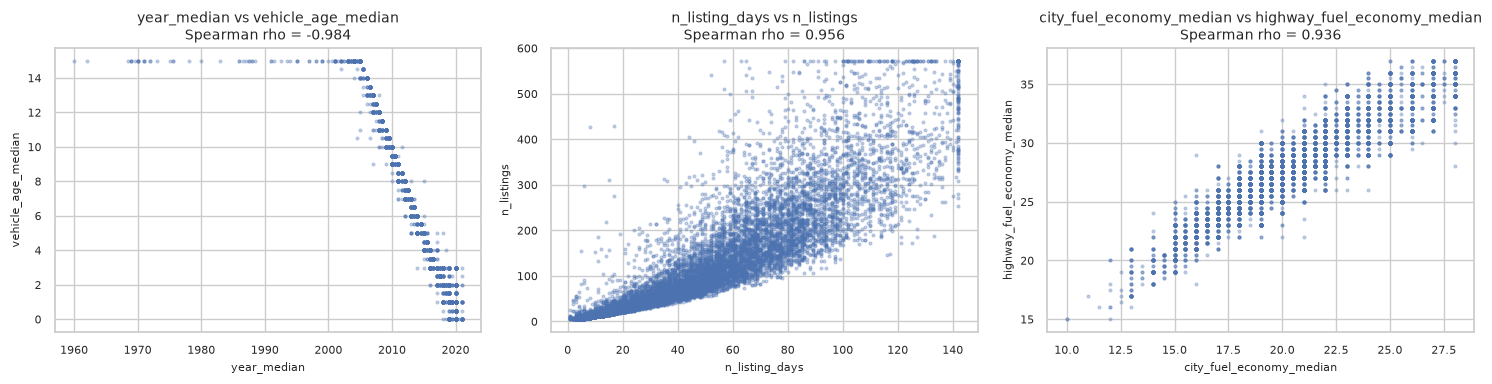

In [22]:
# Scatter plots confirming the near-duplicate pairs
dup_pairs = [
    ('year_median', 'vehicle_age_median'),
    ('n_listing_days', 'n_listings'),
    ('city_fuel_economy_median', 'highway_fuel_economy_median'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (x, y) in zip(axes, dup_pairs):
    ax.scatter(df_clean[x], df_clean[y], s=4, alpha=0.3)
    rho = df_clean[x].corr(df_clean[y], method='spearman')
    ax.set_title(f'{x} vs {y}\nSpearman rho = {rho:.3f}', fontsize=10)
    ax.set_xlabel(x, fontsize=8)
    ax.set_ylabel(y, fontsize=8)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()


### 1.5.2 Spearman correlation matrix heatmap & redundant feature elimination


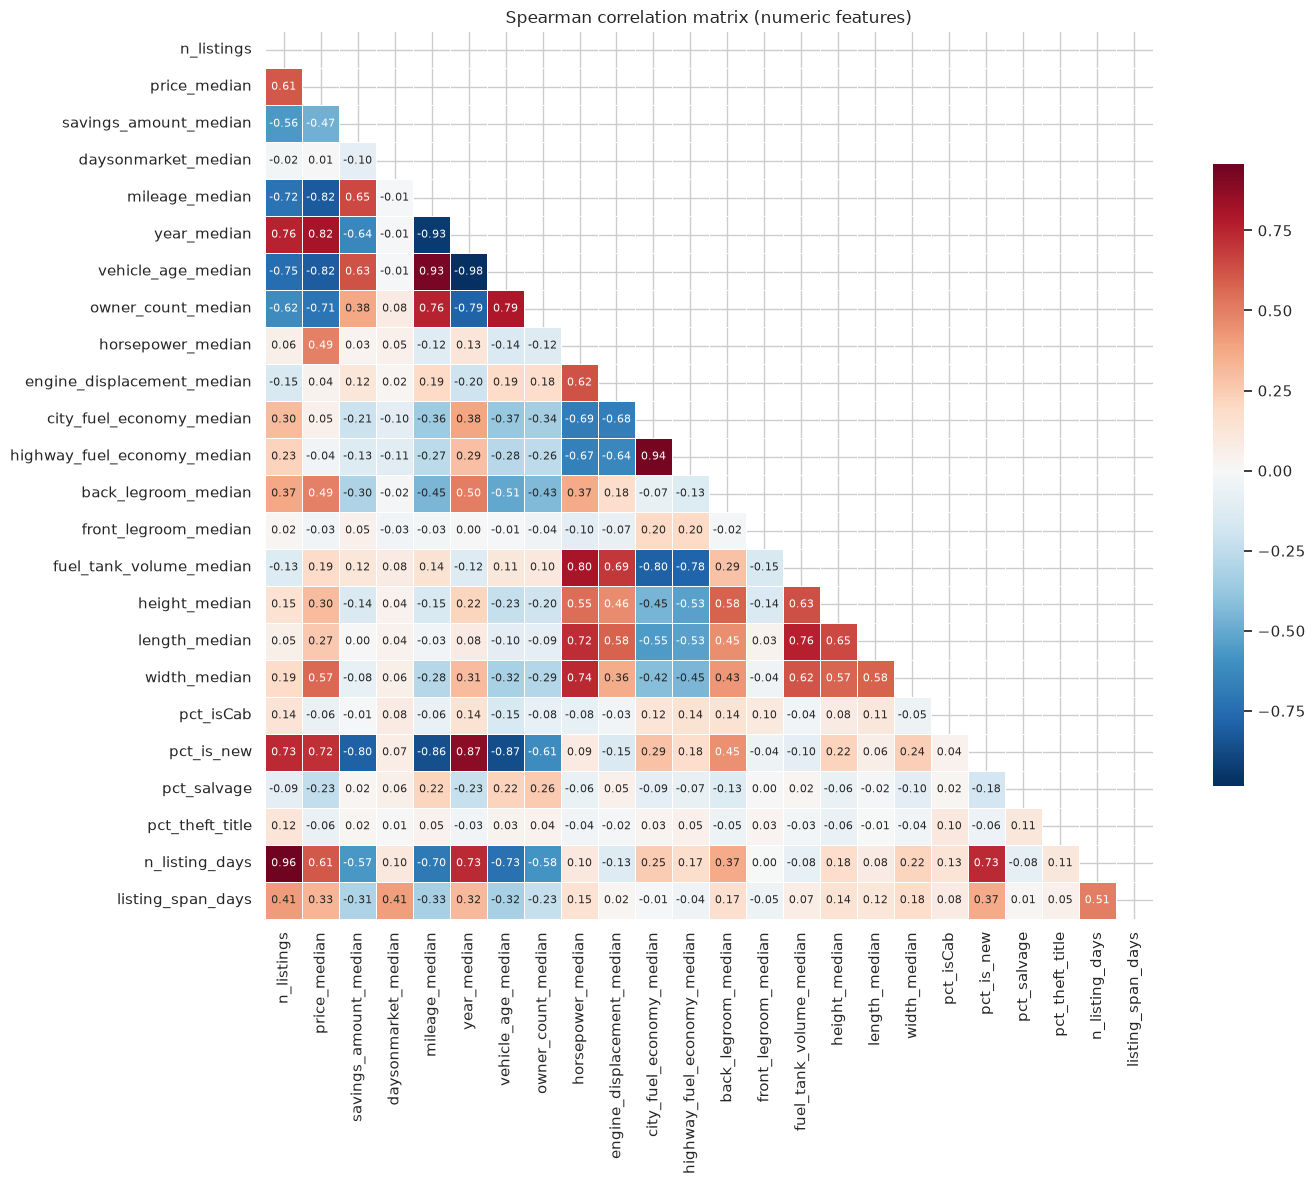

In [23]:
corr = df_clean[num_clean].corr(method='spearman')

plt.figure(figsize=(15, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.7}, annot_kws={"fontsize":8})
plt.title('Spearman correlation matrix (numeric features)')
plt.tight_layout()
plt.show()


In [24]:
# List the strongest correlated pairs (|rho| > 0.8)
pairs = []
cols = corr.columns.tolist()
for i in range(len(cols)):
    for j in range(i):
        r = corr.iloc[i, j]
        if abs(r) > 0.8:
            pairs.append((cols[i], cols[j], round(r, 3)))
pairs = sorted(pairs, key=lambda x: -abs(x[2]))
print('Pairs with |rho| > 0.8:')
for a, b, r in pairs:
    print(f'  {a:28s} vs {b:28s}  rho = {r:+.3f}')


Pairs with |rho| > 0.8:
  vehicle_age_median           vs year_median                   rho = -0.984
  n_listing_days               vs n_listings                    rho = +0.956
  highway_fuel_economy_median  vs city_fuel_economy_median      rho = +0.936
  year_median                  vs mileage_median                rho = -0.932
  vehicle_age_median           vs mileage_median                rho = +0.927
  pct_is_new                   vs year_median                   rho = +0.873
  pct_is_new                   vs vehicle_age_median            rho = -0.867
  pct_is_new                   vs mileage_median                rho = -0.861
  mileage_median               vs price_median                  rho = -0.823
  year_median                  vs price_median                  rho = +0.820
  vehicle_age_median           vs price_median                  rho = -0.815
  fuel_tank_volume_median      vs horsepower_median             rho = +0.805


**Variable elimination.**

Using a threshold of |Spearman rho| > 0.9 on the numeric features:

* `year_median` — near-duplicate of `vehicle_age_median` (rho = −0.984). **Dropped.**
* `n_listing_days` — near-duplicate of `n_listings` (rho = 0.956). **Dropped.**
* `highway_fuel_economy_median` — near-duplicate of `city_fuel_economy_median` (rho = 0.936). **Dropped.**

In addition:

* `engine_displacement_median` — 24.5% missing **and** redundant with
  `fuel_tank_volume_median` (rho = 0.81) / `horsepower_median` (rho = 0.81). **Dropped.**

`mileage_median` vs `vehicle_age_median` (rho = 0.93) is also high, but both are kept:
mileage carries distinct pricing information that age alone does not capture.


In [25]:
eliminate = ['year_median', 'n_listing_days', 'highway_fuel_economy_median', 'engine_displacement_median']
df_final = df_clean.drop(columns=eliminate)
print('Eliminated:', eliminate)
print('\nFinal feature set:', df_final.shape[1], 'columns')
print('\nFinal dtypes:')
df_final.dtypes


Eliminated: ['year_median', 'n_listing_days', 'highway_fuel_economy_median', 'engine_displacement_median']

Final feature set: 28 columns

Final dtypes:


sp_id                         int64
n_listings                  float64
price_median                float64
savings_amount_median       float64
daysonmarket_median         float64
mileage_median              float64
vehicle_age_median          float64
owner_count_median            int64
horsepower_median           float64
city_fuel_economy_median    float64
back_legroom_median         float64
front_legroom_median        float64
fuel_tank_volume_median     float64
height_median               float64
length_median               float64
width_median                float64
pct_isCab                   float64
pct_is_new                  float64
pct_salvage                 float64
pct_theft_title             float64
listing_span_days           float64
dominant_body_type              str
dominant_fuel_type              str
dominant_transmission           str
dominant_listing_color          str
franchise_status                str
new_used_profile                str
seller_rating_class         

## 2. Export the clean dataset

Two outputs are written to `dataset/`:

1. **`seller_info_dm1_2627_clean.csv`** — cleaned values (missing imputed, outliers
   capped, redundant columns removed, correct dtypes, readable categories). This is
   the canonical dataset the next notebooks start from.
2. **`seller_info_dm1_2627_preprocessed.csv`** — the same data fully prepared for
   distance-based models: log1p + Z-score numeric features, one-hot encoded categories.


In [26]:
# --- Export 1: clean dataset (raw but cleaned values) -------------------------
out_clean = 'dataset/seller_info_dm1_2627_clean.csv'
df_final.to_csv(out_clean, index=False)
print('Saved', out_clean, '->', df_final.shape)

# --- Export 2: preprocessed dataset (log1p + z-score + one-hot) --------------
num_final = df_final.select_dtypes(include=[np.number]).drop(columns=['sp_id']).columns.tolist()

# same log-transform rule, recomputed on the final feature set
skew_final = df_final[num_final].skew()
log_final = [c for c in num_final if skew_final[c] > 1 and c != 'owner_count_median']

df_prep = df_final.copy()
for col in log_final:
    df_prep[col] = np.log1p(df_prep[col])
df_prep[num_final] = StandardScaler().fit_transform(df_prep[num_final])
df_prep = pd.get_dummies(df_prep, columns=cat_features, dtype=int)

out_prep = 'dataset/seller_info_dm1_2627_preprocessed.csv'
df_prep.to_csv(out_prep, index=False)
print('Saved', out_prep, '->', df_prep.shape)


Saved dataset/seller_info_dm1_2627_clean.csv -> (13843, 28)
Saved dataset/seller_info_dm1_2627_preprocessed.csv -> (13843, 58)


In [27]:
# Sanity check: reload and verify no nulls, no wrong types, target intact
check = pd.read_csv(out_clean)
print('Reloaded clean CSV:', check.shape)
print('Nulls:', check.isna().sum().sum())
print('Target classes preserved:')
print(check['seller_rating_class'].value_counts().to_string())
print('\nFirst 3 rows:')
check.head(3)


Reloaded clean CSV: (13843, 28)
Nulls: 0
Target classes preserved:
seller_rating_class
medium    7577
high      3687
low       2579

First 3 rows:


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,vehicle_age_median,owner_count_median,horsepower_median,city_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771,30.000,"6,700.000",431.000,13.000,"174,295.000",9.000,2,258.500,17.000,38.650,41.300,21.000,68.900,195.350,77.100,0.133,0.000,0.000,0.000,156.000,suv_crossover,gasoline,automatic,gray,independent,used_only,medium
1,336590,17.000,"10,995.000",505.000,24.000,"87,589.000",7.000,2,182.000,21.000,37.300,41.400,15.900,64.700,180.300,72.500,0.059,0.000,0.000,0.000,589.000,suv_crossover,gasoline,automatic,silver,independent,used_only,medium
2,392016,18.000,"7,645.000",632.000,43.000,"151,434.000",9.500,2,205.000,20.000,35.500,41.700,17.500,58.100,188.200,72.000,0.111,0.000,0.000,0.000,97.000,sedan,gasoline,automatic,blue,independent,used_only,low


## Summary

* **Data types fixed** — `sp_id` (float → int), `owner_count_median` (float → int),
  transmission abbreviations expanded (`a`→automatic, `m`→manual).
* **Columns removed** — `dominant_wheel_system` (76% missing), `engine_displacement_median`
  (24.5% missing + redundant), `year_median`, `n_listing_days`, `highway_fuel_economy_median`
  (redundant). 33 → 28 columns.
* **Missing values** — median imputation for numeric (<0.3% per column); `unknown` kept as a
  legitimate category.
* **Outliers / noise** — semantic fix (`back_legroom_median == 0`) + winsorization at the 99th
  percentile (no rows deleted).
* **Transformation** — log1p for highly skewed features, Z-score standardization, one-hot encoding.
* **Output** — `seller_info_dm1_2627_clean.csv` (canonical) and
  `seller_info_dm1_2627_preprocessed.csv` (model-ready).
